# Telco Customer Churn - Customer Analytics & Churn Predition

Bu projede,bir telekomünikasyon şirketine ait müşteri verilerini analiz ederek müşteri davranışlarının incelenmesi ve müşterilerin ayrılmasına neden olabilecek faktörlerin belirlenmesi amaçlanmaktadır.
## Proje kapsamında veri analizi sürecinin farklı aşamaları uygulanacaktır:

 Python ve Pandas ile veri analizi
 Veri temizleme ve veri ön işleme
 SQL ile veri sorgulama ve analiz
 Keşifsel Veri Analizi (EDA)
 Veri görselleştirme
 İstatistiksel analiz
 Özellik mühendisliği (Feature Engineering)
 Makine öğrenmesi
 Model değerlendirme
 Sonuçların yorumlanması ve iş içgörüleri

Bu Notebook aynı zamanda veri analitiği öğrenirken tuttuğum uygulamalı çalışma notlarını içermektedir.

## İş Problemi

Müşteri kaybı (Customer Churn), telekomünikasyon şirketleri açısından önemli bir problemdir. Müşterilerin hangi özelliklere ve davranışlara sahipken şirketten ayrılma eğiliminde olduklarının anlaşılması, müşteri kaybının analiz edilmesine ve gelecekteki müşterilerin davranışlarının tahmin edilmesine yardımcı olabilir.

Bu projenin temel amacı;

 müşterilerin genel özelliklerini incelemek,
 müşteri davranışlarını analiz etmek,
 müşteri kaybı ile ilişkili değişkenleri belirlemek,
 farklı değişkenler arasındaki ilişkileri görselleştirmek,
 elde edilen bulguları yorumlamak
 ve son aşamada makine öğrenmesi modelleri kullanarak müşteri kaybını tahmin etmektir.

Temel Araştırma Sorusu

“Müşterilerin hangi özellikleri ve hizmet kullanım davranışları müşteri kaybı ile ilişkilidir ve bu bilgiler kullanılarak müşteri kaybı tahmin edilebilir mi?”

# Kütüphanelerin Yüklenmesi

Veri analizi sürecinde farklı işlemler için çeşitli Python kütüphanelerinden yararlanacağım.

Bu projede temel olarak:

 Pandas: Veri setini okumak, düzenlemek, filtrelemek ve analiz etmek
 NumPy: Sayısal işlemler ve diziler üzerinde çalışmak
 Matplotlib: Veri görselleştirmek
 Seaborn: İstatistiksel ve daha gelişmiş görselleştirmeler oluşturmak

için kullanılacaktır.

İlerleyen aşamalarda makine öğrenmesi için farklı kütüphaneler de projeye dahil edilecektir.

In [45]:
import pandas as pd 
import numpy  as np 
import matplotlib.pyplot as plt 
import seaborn as sns

# Veri Setinin Yüklenmesi

Bu projede kullanılacak veri seti Excel formatında olduğu için Pandas’ın read_excel() fonksiyonunu kullanacağım.

Veri setini bir DataFrame içerisine aktararak sonraki aşamalarda veri temizleme, keşifsel veri analizi (EDA), görselleştirme ve makine öğrenmesi çalışmalarında kullanacağım.

DataFrame, satır ve sütunlardan oluşan tablo biçimindeki verileri Python içerisinde işlememizi sağlayan temel Pandas yapılarından biridir.


In [46]:
df=pd.read_excel("Telco_customer_churn.xlsx")

head() bize DataFrame'in ilk 5 satırını gösterir.

In [47]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


# Veri Setini Tanıma

Veri setini analiz etmeye başlamadan önce veri setinin boyutunu, sütunlarını ve veri tiplerini incelemek gerekir.

Bu aşamada:

 Veri setinde kaç satır ve sütun olduğunu,
 Hangi değişkenlerin bulunduğunu,
 Değişkenlerin hangi veri tipinde olduğunu,
 Eksik değerlerin bulunup bulunmadığını

kontrol edeceğim.

Bu kontroller, sonraki veri temizleme ve analiz aşamalarının doğru şekilde planlanmasına yardımcı olacaktır.


In [48]:
df.shape 
#7043 müşteri 33 adet değişken

(7043, 33)

# Veri Klaitesinin Kontrolü
Veri boyutunu öğrendikten sonra veri kalitesine bakılır.Bu şekilde veri analize hazır mı değil mi ölçülür.

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

# Eksik Değerlerin İncelenmesi

Veri setinin genel yapısını inceledikten sonra değişkenlerde eksik gözlem bulunup bulunmadığını kontrol edeceğim.

Eksik değerler; yapılacak istatistiksel analizleri, görselleştirmeleri ve makine öğrenmesi modellerini etkileyebilir. Ancak her eksik değer hatalı veri anlamına gelmez. Eksikliğin hangi değişkende ve hangi iş kuralı nedeniyle oluştuğunu anlamak gerekir.

Bu nedenle eksik değerleri önce sütun bazında sayacak, daha sonra gerekli durumlarda eksik değerlerin nedenini inceleyeceğim.

In [50]:
df.isnull().sum().sort_values(ascending=False)

Churn Reason         5174
CustomerID              0
Count                   0
State                   0
Country                 0
Zip Code                0
Lat Long                0
Latitude                0
City                    0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Longitude               0
Internet Service        0
Online Security         0
Device Protection       0
Online Backup           0
Streaming TV            0
Streaming Movies        0
Contract                0
Tech Support            0
Paperless Billing       0
Payment Method          0
Total Charges           0
Monthly Charges         0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
dtype: int64

# Tekrarlanan Kayıtların Kontrolü

Veri setinde aynı kaydın birden fazla kez bulunup bulunmadığını kontrol edeceğim.

Tekrarlanan kayıtlar analizlerde bazı müşterilerin birden fazla kez sayılmasına ve dolayısıyla sonuçların yanlış yorumlanmasına neden olabilir.

Bu nedenle veri temizleme işlemine geçmeden önce duplicate kayıtların varlığını kontrol edeceğim.

Burada henüz herhangi bir kaydı silmeyeceğim. Öncelikle kaç tekrar olduğunu tespit edeceğim.


In [51]:
df.duplicated().sum()
#aynı olan satır bulunmuyor

np.int64(0)

#  Değişkenlerin İncelenmesi

Veri kalitesi kontrollerinin ardından veri setinde bulunan değişkenleri inceleyeceğim.

Bir veri analizi projesinde her değişkenin neyi temsil ettiğini bilmek, yapılacak analizlerin doğru şekilde planlanması açısından önemlidir.

Bu aşamada sütun isimlerini listeleyerek veri setinde hangi müşteri bilgilerine sahip olduğumuzu inceleyeceğim.


In [52]:
df.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='object')

# Değişkenlerin İşlevlerine Göre Gruplandırılması

Veri setindeki değişkenleri yalnızca veri tiplerine göre değil, işlevlerine ve temsil ettikleri müşteri bilgilerine göre de incelemek gerekir.

Bu sınıflandırma, ilerleyen aşamalarda hangi değişkenleri hangi analizlerde kullanacağımızı belirlememize yardımcı olacaktır.

Değişkenleri genel olarak aşağıdaki gruplarda değerlendirebiliriz:

1. Müşteri ve konum bilgileri

 CustomerID
 Country
 State
 City
 Zip Code
 Lat Long
 Latitude
 Longitude

2. Demografik bilgiler

 Gender
 Senior Citizen
 Partner
 Dependents

3. Müşteri ilişkisi ve hizmet kullanımı

 Tenure Months
 Phone Service
 Multiple Lines
 Internet Service
 Online Security
 Online Backup
 Device Protection
 Tech Support
 Streaming TV
 Streaming Movies

4. Sözleşme ve ödeme bilgileri

 Contract
 Paperless Billing
 Payment Method

5. Finansal değişkenler

 Monthly Charges
 Total Charges
 CLTV

6. Churn ile ilgili değişkenler

 Churn Label
 Churn Value
 Churn Score
 Churn Reason

7. Teknik/yardımcı değişken

* Count

Bu gruplandırma kesin bir analiz kararı değildir. İlerleyen aşamalarda değişkenlerin veri yapısını ve iş anlamını daha ayrıntılı inceleyerek hangi değişkenlerin analizlerde kullanılacağına karar vereceğim.


In [53]:
#nunique : bize her sütunda kaç farklı değer  bulunduğunu gösterecek

df.nunique().sort_values()

Count                   1
Country                 1
State                   1
Phone Service           2
Dependents              2
Partner                 2
Senior Citizen          2
Gender                  2
Churn Value             2
Paperless Billing       2
Churn Label             2
Multiple Lines          3
Internet Service        3
Online Backup           3
Online Security         3
Tech Support            3
Contract                3
Streaming Movies        3
Streaming TV            3
Device Protection       3
Payment Method          4
Churn Reason           20
Tenure Months          73
Churn Score            85
City                 1129
Monthly Charges      1585
Longitude            1651
Latitude             1652
Lat Long             1652
Zip Code             1652
CLTV                 3438
Total Charges        6531
CustomerID           7043
dtype: int64

# Hedef Değişkenin İncelenmesi

Bu projedeki temel iş problemi müşterilerin şirketten ayrılma davranışını (Churn) anlamaktır.

Bu nedenle analizimizin ilerleyen aşamalarında hedef değişken olarak kullanacağımız Churn Label değişkeninin dağılımını inceleyeceğim.

Öncelikle müşterilerin ne kadarının şirketten ayrıldığını ve ne kadarının şirkette kaldığını belirlemek istiyorum.

Bu kontrol, veri setindeki sınıfların dengeli olup olmadığını anlamak ve ileride kurulacak makine öğrenmesi modellerini doğru değerlendirmek açısından önemlidir.


In [54]:
df["Churn Label"].value_counts()
#value_counts():bu sütunda bulunan her farklı değerin kaç kez tekrar ettiğini sayıyor.
#Çıktıya göre:5174 kişi ayrılmamış 1869'u ayrılmış

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

# Churn Oranının Hesaplanması

Müşteri sayılarını tek başına incelemek, churn davranışının veri setindeki büyüklüğünü tam olarak göstermeyebilir.

Bu nedenle churn eden müşterilerin toplam müşteriler içerisindeki oranını hesaplayacağım.

Churn oranı, şirketin mevcut müşteri tabanındaki ayrılma seviyesini anlamak için temel göstergelerden biridir.

Bu oranı yüzde olarak ifade ederek ilerleyen analizlerde farklı müşteri gruplarının churn oranlarıyla karşılaştıracağım.



In [55]:
df["Churn Label"].value_counts(normalize=True)*100
#normalize =true -> bana adetleri değil,toplam içerisindeki oranları ver
#No:%73,46
#Yes:%26,54
#Bu veri setindeki her 100 müşterinin yaklaşık 73'ü şirkette kalmış,27 ayrılmış.
#Makine öğrenmesi açısından hedef değişkenimiz tamamen dengeli değil.
# No sınıfı ,Yes sınıfından oldukça fazla:Modeli kurarken önemlidir çünkü model herkese No dese bile 
#yaklaşık %73 doğruluk elde edebilir.Yani sadece accuracy'ye bakmamamız gerektiğini şimdiden biliyoruz.

Churn Label
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

# Churn Dağılımının Görselleştirilmesi

Churn değişkeninin sayısal dağılımını inceledikten sonra, sınıfların dağılımını görsel olarak da inceleyeceğim.

Görselleştirme, churn eden ve etmeyen müşterilerin toplam müşteri kitlesindeki paylarını daha kolay karşılaştırmamızı sağlayacaktır.

Bu grafik aynı zamanda hedef değişkenin sınıf dağılımındaki dengesizliği görsel olarak değerlendirmemize yardımcı olacaktır.

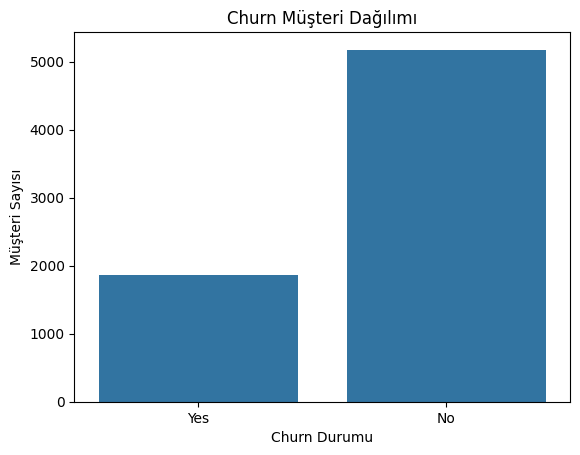

In [56]:
sns.countplot(data=df,x='Churn Label') 
#sns.countplot->kategorik bir değişkenin kaç kez tekrarlandığını sütun grafik olarak gösterir# 

plt.title("Churn Müşteri Dağılımı")
plt.xlabel("Churn Durumu")
plt.ylabel("Müşteri Sayısı")

plt.show()

# 4.8 Müşteri Kimliklerinin Kontrolü

Önceki adımda veri setinde birebir aynı olan satırları kontrol ettik ve tekrar eden satır bulunmadığını gördük. Ancak bu kontrol, aynı müşterinin farklı bilgiler içeren birden fazla kaydının olup olmadığını göstermez.

Bu nedenle CustomerID değişkenini ayrıca kontrol edeceğiz. Her müşterinin veri setinde tek bir kaydı olması, müşteri bazlı analizlerin doğru yapılabilmesi açısından önemlidir.


In [57]:
df["CustomerID"].duplicated().sum()
#Buarda 0 tekrarlanan CustomerID bulunmadığını söyler.7043 müşterinin customerıd benzersiz

np.int64(0)

# Sabit Değerli Değişkenlerin İncelenmesi

Bir değişkenin veri setindeki tüm gözlemlerde aynı değere sahip olması, analiz açısından o değişkenin ayırt edici bir bilgi taşımadığını gösterebilir.

Önceki incelemede Count, Country ve State değişkenlerinin yalnızca birer farklı değere sahip olduğunu gördük. Şimdi bu sütunlarda gerçekten hangi değerlerin bulunduğunu kontrol edeceğiz.

Bu aşamada herhangi bir sütunu silmiyoruz. Önce verinin ne ifade ettiğini anlayacağız; değişkenlerin analizde kullanılıp kullanılmayacağına daha sonra karar vereceğiz.


In [58]:
df[["Count","Country","State"]].drop_duplicates()
#çıktıya göre bütün kayıtlarda bütün müşteriler aynı bölgedeler yani churn durumuna bakarken state bize ayrım yaptırmaz.

,Count,Country,State
0,1,United States,California


# Veri Tiplerinin Kontrolü

Veri setindeki değişkenlerin doğru veri tipinde olup olmadığını kontrol etmek, analiz öncesindeki önemli veri kalite adımlarından biridir.

Sayısal değişkenlerin sayısal, kategorik değişkenlerin ise kategorik/metinsel olarak tanımlanması; hesaplamaların, görselleştirmelerin ve ilerleyen aşamadaki makine öğrenmesi süreçlerinin doğru çalışması açısından önemlidir.

Bu aşamada herhangi bir veri tipini değiştirmiyoruz. Öncelikle veri setinin mevcut durumunu inceleyeceğiz.


In [59]:
df.dtypes



CustomerID            object
Count                  int64
Country               object
State                 object
City                  object
Zip Code               int64
Lat Long              object
Latitude             float64
Longitude            float64
Gender                object
Senior Citizen        object
Partner               object
Dependents            object
Tenure Months          int64
Phone Service         object
Multiple Lines        object
Internet Service      object
Online Security       object
Online Backup         object
Device Protection     object
Tech Support          object
Streaming TV          object
Streaming Movies      object
Contract              object
Paperless Billing     object
Payment Method        object
Monthly Charges      float64
Total Charges         object
Churn Label           object
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason          object
dtype: object

# Churn Reason Eksik Değerlerini inceleyelim 
Burada eksik değerlerin mantığını öğrenmeye çalışıcağım.Yani 5174 adet eksik görmüştük bu gerçekten churn olmayan müşterilerde mi boş yoksa churn olanlar mıydı.Eğer müşteri ayrılmadıysa ayrılma sebebi olması da beklenmeyebilir.

In [60]:
pd.crosstab(df["Churn Label"],df["Churn Reason"].isna())
#churnlabel=yes,no müşteri ayrılmış,ayrılmamış
#churnreason müşteri ayrılma nedeni
#.isna():değer eksikse->true değer varsa->false diyor.hücre boşmu diye sorar.
#pd.crosstab():karşılaştırmayı yapan kısım yani iki değişkeni çapraz tablo halinde karşılaştırır.
#churnlabelda reason kısmı eksik olmayan olan kaç kişi var.
#false:boş değil dolu
#true:boş

Churn Reason,False,True
Churn Label,,
No,0,5174
Yes,1869,0


Çıktıya göre churn=no olup 5174 kişinin reason bilgisi yok.
churn=yes olup 1869 müşterinin tamamında reason kısmı dolu.
Müşteri ayrılmamışsa ayrılma sebebi yok.Ayrıldıysa da sebebi mevcut.

# Kategorik değerlerde tutarsızlık var mı?
Kategorik sütunların içinde hangi değerler var.
Gender:Male-Female !ama yanlışlıkla Male-Female-female-Male

In [61]:
df["Gender"].value_counts()
#value_counts():sütunda her farklı değerin kaç kez bulunduğunu sayıyor
#bunu nuniuque ile bakmıştık tammamın kaç değer var diye

Gender
Male      3555
Female    3488
Name: count, dtype: int64

In [62]:
#gender sütununda eksik değer var mı diye bakmak isteseydik
df["Gender"].isna().sum()

np.int64(0)

# Kaç farklı sözleşme türü var ve her türde kaç müşteri var?
Churn ksımını analiz ederken bakacağımız bir kısım olacak.Yani hangi sözleşmede churn oldu olmadı gibi.

In [63]:
df["Contract"].value_counts() #her tür kaç defa gibi.

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

# İnternet hizmet türleri inceleyelim


In [64]:
df["Internet Service"].value_counts()
#üç kategori var burada en fazla tercih edilen fiber optic olmuş sonra dsl 1536 kişi hiç bir şey kullanmamış
#bu durumla ilişkili churn label kısmını eşleştirip bakmalıyız hangi hizmeti alanlar ayrılmış


Internet Service
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

# Payment Method ödeme yöntemlerini kontrol edelim


In [65]:
df["Payment Method"].value_counts()
#7043 müşterinin de ödeme yöntemi sistemde kayıtlı 

Payment Method
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

# Sayısal Değişkenlerin Genel Dağılımının İncelenmesi

Bu aşamada minimum, maksimum, ortalama, standart sapma ve çeyreklik değerleri kullanarak değişkenlerin hangi aralıklarda bulunduğunu ve olağandışı değerler olup olmadığını kontrol edeceğiz.

Henüz herhangi bir değeri değiştirmeyeceğiz veya veri setinden silmeyeceğiz. Öncelikle mevcut verinin yapısını anlayacağız.


In [66]:
df[["Tenure Months","Monthly Charges","Total Charges","Churn Score","CLTV"]].describe()

,Tenure Months,Monthly Charges,Churn Score,CLTV
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,58.699418,4400.295755
std,24.559481,30.090047,21.525131,1183.057152
min,0.000000,18.250000,5.000000,2003.000000
25%,9.000000,35.500000,40.000000,3469.000000
50%,29.000000,70.350000,61.000000,4527.000000
75%,55.000000,89.850000,75.000000,5380.500000
max,72.000000,118.750000,100.000000,6500.000000


Burada 
Tenure Months :müşteri kaç aydır bulunuyor
Monthly Charges:Müşterinin ödediği aylık ücret
Total Charges:Müşterinin şimdiye kadar ödedeği ücret
Churn Score:Müşterinin ayrılma eğilimini iafede eden skor
CLTV:Customer Lifetime Value->müşteri yaşam boyu değeri yani bir müşterinin ilişkisi boyunca sağladığı toplam ekonomik değerdir

mean:ortalama 7043 kişinin arıtmetik ort yaklaşık 32 ay,64.76$ bunların aylık ödediği bunların ortalama churn score değeri 58.69

std:standart sapma  burada müşteri değerlerinin ortalamadan ne kadar dağıldığını anlatır.
tenure ort 32 ay std 24.5 ay müşteri kullanım sürelerinin 32 ayın etrafında oldukça geniş bir şekilde dağıldıpını gösterir.

min :en düşük örn en düşük aylık ücret 18.25$ en düşük churn skoru 5
en düşük cltv 2003
bunların hepsi aynı müşteri değil

25%, 50%, 75% neden var?
Bunlara çeyreklikler (quartiles) deniyor.
Basitçe:
 25% (Q1): Müşterilerin %25’i bu değerin altında/eşit.
 50% (Q2 / Median): Müşterilerin %50’si bunun altında/eşit, %50’si üstünde/eşit.
 75% (Q3): Müşterilerin %75’i bunun altında/eşit.

Örneğin Tenure için 25% değeri 9 ay :Müşterilerin %25’i 9 ay veya daha az süredir müşteri.

50% değeri 29 ay :Müşterilerin yarısı 29 ay veya daha az, diğer yarısı 29 ay veya daha fazla süredir müşteri.

75% değeri 55 ay :Müşterilerin %75’i 55 ay veya daha az süredir müşteri.

Bunlar ortalama değil.

max — Maksimum

Tenure Months max = 72 Veri setindeki en uzun süre müşterisi olan kişinin 72 aylık olduğu anlamına gelir.

Monthly Charges max = 118.75 Veri setindeki tek bir müşterinin aylık ücretinin en yüksek 118.75 olduğu anlamına gelir.

# 72 aylık müşterilerin ortalama faturası 118.75 demek değildir.

Churn Score max = 100 En yüksek Churn Score’a sahip müşterinin skoru 100.

CLTV max = 6.500 veri setindeki en yüksek CLTV değerine sahip müşterinin CLTV’si 6.500.

Bunların hepsi tek bir kişiye ait olmak zorunda da değil.

Örneğin maksimum Monthly Charges’a sahip kişi ile maksimum CLTV’ye sahip kişi farklı müşteriler olabilir.

count	Kaç dolu kayıt var?
mean	Ortalama değer ne?
std	Değerler ortalamadan ne kadar dağılıyor?
min	En küçük değer ne?
25%	Alt %25’lik dilimin sınırı
50%	Medyan
75%	Alt %75’lik dilimin sınırı
max	En büyük tekil değer


# Sayısal değerlerin mantıksal aralık kontrolü 

mantıksız imkansız değer var mı?
şimdi negatif olmaması gerekn şeylerin olup olmadığına bakıyoruz.


# !Total Charges datatype:object bu yüzden tipini inceleyeceğiz


In [67]:
df["Total Charges"].value_counts(dropna=False).tail(20)
#dropna=false :eksik NaN değerleride saymaya dahil et normalde value counts 
# saymaz çünkü kaç değerden kaç tane var diye bakar

Total Charges
1020.75    1
826        1
239        1
108.15     1
6844.5     1
3626.35    1
1679.4     1
931.55     1
4326.25    1
263.05     1
39.25      1
3316.1     1
2625.25    1
1495.1     1
743.3      1
1419.4     1
1990.5     1
7362.9     1
346.45     1
820.5      1
Name: count, dtype: int64

# Sayıya dönüştürülemeyen değerin tespiti
 total chargesi tamammını sayıya çevirip bakalım.
 geçiçi bir şekilde değiştireceğiz
 

In [68]:

total_charges_numeric=pd.to_numeric(df["Total Charges"],errors="coerce")
total_charges_numeric.isna().sum()
#pd.to_numeric ():değerleri sayıya çevirmeyi dener
#errors=coerce :sayı olmayan bir değer varsa bulursa hata vermek yerine NaN yapar.
#total_charges_numeric diyerekte orjinal sütuna dokunmadan geçiçi sayısal verisyon oluşturur.
#isna() : kaç adet NaN olduğunu söyler
#çıktıya göre Total Charges sütununda 11 tane değer sayısal formata dönüştürelemedi
#BUNU TESPİT ETTİK BU DEĞERLERİN ORİJİNAL HALLERİNİ TESPİT EDECEĞİZ 

np.int64(11)

In [69]:
df.loc[total_charges_numeric.isna(),"Total Charges"]

# total_charges_numeric.isna(),"Total Charges"] sayıya çevrilmeyen 11 adet değeri getirdi
#df.loc bu değerleri satırlarının orijinal Total Cahrges değerlerini getiriyor 

2234     
2438     
2568     
2667     
2856     
4331     
4687     
5104     
5719     
6772     
6840     
Name: Total Charges, dtype: object

# eksik değerlerin incelenmesi için detay bakıyoruz

In [70]:
df.loc[total_charges_numeric.isna(),["CustomerID","Tenure Months","Monthly Charges","Total Charges","Churn Label"]]

#Tenure Months kısmına bakınca anlıyoruz ki yeni gelen müşteriler.
#pandas boş hücreler nedeniyle sütunu object olarak okumuş


,CustomerID,Tenure Months,Monthly Charges,Total Charges,Churn Label
2234,4472-LVYGI,0,52.55,,No
2438,3115-CZMZD,0,20.25,,No
2568,5709-LVOEQ,0,80.85,,No
2667,4367-NUYAO,0,25.75,,No
2856,1371-DWPAZ,0,56.05,,No
4331,7644-OMVMY,0,19.85,,No
4687,3213-VVOLG,0,25.35,,No
5104,2520-SGTTA,0,20.00,,No
5719,2923-ARZLG,0,19.70,,No
6772,4075-WKNIU,0,73.35,,No


# Total Charges sütununu sayısal formata çevirme
boş değerler NaN olarak korunacak ve sıfır ile doldurulmayacaktır.

In [71]:
df["Total Charges"]=pd.to_numeric(df["Total Charges"],errors="coerce")

In [72]:
df["Total Charges"].dtype
# tekrardan doğrulamak amacıyla bakıyoruz

dtype('float64')

In [73]:
#Mantık analizine şimdi geçiyoruz
print ("Negatif Tenure:",(df["Tenure Months"]<0).sum())
print ("Negatif Monthly Charges:",(df["Monthly Charges"]<0).sum())
print ("Negatif Total Charges:",(df["Total Charges"]<0).sum())
print ("Churn Score < 0:",(df["Churn Score"]<0).sum())
print ("Churn Score > 100:",(df["Churn Score"]>100).sum())
print ("Negatif CLTV:",(df["CLTV"]<0).sum())

Negatif Tenure: 0
Negatif Monthly Charges: 0
Negatif Total Charges: 0
Churn Score < 0: 0
Churn Score > 100: 0
Negatif CLTV: 0


#  Veri Dönüşümü Sonrası Eksik Değerlerin Yeniden Kontrolü

Total Charges değişkenini sayısal formata dönüştürdükten sonra eksik değerleri tekrar kontrol ediyoruz.

Bunun nedeni, veri tipi dönüşümü sırasında daha önce boş veya sayısal olmayan değerlerin NaN olarak işaretlenebilmesidir.



In [74]:
df.isnull().sum().sort_values(ascending=False)
#sort_values(ascending=False) en fazla eksik değeri olanı listede en başta göster

Churn Reason         5174
Total Charges          11
CustomerID              0
Count                   0
Country                 0
Zip Code                0
Lat Long                0
State                   0
City                    0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Latitude                0
Longitude               0
Internet Service        0
Multiple Lines          0
Online Security         0
Online Backup           0
Streaming TV            0
Streaming Movies        0
Device Protection       0
Tech Support            0
Paperless Billing       0
Contract                0
Monthly Charges         0
Payment Method          0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
dtype: int64

# Data Cleaning / Veri Temizleme

Veri kalitesi kontrollerinde veri setindeki eksik değerleri, veri tipi problemlerini, tekrarları ve mantıksal tutarsızlıkları inceledik.

Bu aşamada ise analiz ve modelleme için veri setini uygun hale getireceğiz.

Veri temizleme sürecinde herhangi bir değeri doğrudan silmek veya doldurmak yerine, öncelikle problemin kaynağını ve iş mantığındaki anlamını değerlendireceğiz.

İlk olarak Total Charges değişkenindeki 11 eksik değeri ele alacağız. Bu değerlerin tamamının Tenure Months = 0 olan müşterilere ait olduğunu daha önce tespit ettik.

Bu nedenle bu değerlerin nasıl ele alınacağına karar vermeden önce ilgili kayıtların durumunu tekrar inceleyeceğiz.

In [75]:
df.loc[df["Total Charges"].isna(),
       ["CustomerID","Tenure Months","Monthly Charges","Total Charges","Churn Label"]]
#df.loc sadece bu satırları seç
#df["Total Charges"].isna() burada boş olanları getir

,CustomerID,Tenure Months,Monthly Charges,Total Charges,Churn Label
2234,4472-LVYGI,0,52.55,NaN,No
2438,3115-CZMZD,0,20.25,NaN,No
2568,5709-LVOEQ,0,80.85,NaN,No
2667,4367-NUYAO,0,25.75,NaN,No
2856,1371-DWPAZ,0,56.05,NaN,No
4331,7644-OMVMY,0,19.85,NaN,No
4687,3213-VVOLG,0,25.35,NaN,No
5104,2520-SGTTA,0,20.00,NaN,No
5719,2923-ARZLG,0,19.70,NaN,No
6772,4075-WKNIU,0,73.35,NaN,No


# Total Charges eksik değerlerin ele alırsak
Total charges değişkeninde 11 eksik değer var bu değerlerin tenure months bilgisine bakınca gördük ki 0 ayrıca monthly charges de mevcut her biri için eksikliğin yeni müşterilere ait olduğunu gördük.Bu nedenle doğrulanmamış bir değer üretilmemesi için bu değerleri NaN olarak korumalıyız.

# Sabit değişkenleri belirleme
Sabit değişkenleri yani her kes için aynı olan değerlerin churn davranışında bize ayrım yapabileceğimiz bir bilgi vermez.
Bunları belirleyip modelleme aşamasında kullanmayacağız.


In [76]:
df[["Count","Country","State"]].nunique()
#nunique():her sütun için kaç farklı değer var 
#hepsi için 1 sonucunu aldık yani bunlar sabit değişkenler


Count      1
Country    1
State      1
dtype: int64

# Sabit Değişkenlerin Çıkarılması

Count, Country ve State değişkenlerinin her birinde yalnızca tek bir farklı değer bulunduğu doğrulanmıştır.

Bu değişkenler müşteri bazında herhangi bir farklılık içermediği için churn analizine katkı sağlayacak ayırt edici bilgi taşımamaktadır.

Bu nedenle analiz ve modelleme sürecini sadeleştirmek amacıyla bu üç değişken veri setinden çıkarılacaktır.

Not: Orijinal ham veri dosyası değiştirilmemektedir. Yaptığımız işlem notebook içerisindeki çalışma veri seti df üzerinde gerçekleştirilmektedir.


In [77]:
df=df.drop(columns=["Count","Country","State"])
#df.drop:veri setinden bir şeyler çıkarmamızı sağlar.


In [78]:
df.shape
#33 sutun değişken vardı şimdi 30 tane kaldı

(7043, 30)

# CustomerID Değişkeninin Değerlendirilmesi

CustomerID her müşteri için benzersiz bir kimlik bilgisidir. Bu değişken müşterileri birbirinden ayırt etmek için gereklidir; ancak müşterinin churn davranışı hakkında doğrudan anlamlı bir özellik taşımaz.

Makine öğrenmesi modellerinde benzersiz kimlik bilgilerinin kullanılması, modelin gerçek müşteri davranışlarını öğrenmek yerine kimlik değerlerinden anlamsız örüntüler öğrenmesine neden olabilir.

Bu nedenle CustomerID değişkenini analiz ve modelleme özelliklerinden ayıracağız.

Ancak müşteri bazlı takip veya sonuçların hangi müşteriye ait olduğunu görmek gerektiğinde kimlik bilgisi yararlı olabileceğinden, ham veri setindeki varlığını koruyacağız.


In [79]:
#benzeriz mi diye doğrulayalım
df["CustomerID"].nunique()

# burada 7043 müşteri için benzersiz id var şimdilik silmiyoruz fakat modelleme aşamasında özellik olara vermeyeceğiz


7043

# Target ve Data Leakage Kontrolü
tahmin etmek istediğimiz değişken Churn Label’dır.

Ancak veri setinde churn sonucu ile doğrudan ilişkili başka değişkenler de bulunmaktadır. Bu değişkenlerin modelleme sırasında kullanılması, modelin müşterinin davranışlarını öğrenmek yerine hedef değişken hakkında zaten mevcut olan bilgiyi kullanmasına neden olabilir.

Bu durum data leakage (veri sızıntısı) olarak adlandırılır.

Bu nedenle modelleme öncesinde Churn Label ile ilişkili olabilecek değişkenleri tek tek inceleyeceğiz.

İlk olarak Churn Value değişkenini inceleyeceğiz.


In [80]:
pd.crosstab(df["Churn Label"],df["Churn Value"])
#pd.crosstab():iki kategorik değişkenin birbirleriyle nasıl eşleştiğini gösterir.
#yani churn label no olan müşterilerin churn value değeri ne? aynı zamanda yes olanların ne?
#Çıktıya göre churn label : no churn value değeri:0 churn label :yes churn value:1 yani ayrı bilgiler
#  değil labelların 0 ve 1 olarak ifade edil  
# Modele şunu verdiğimizde value=1 model zaten label yes diyecek.
# model diğer verilere bakmadan direk karar vericek churn sonucu bir verildi yes kararını verir.
    


Churn Value,0,1
Churn Label,,
No,5174,0
Yes,0,1869


#  Değişkenler arasındaki ilişkiyi nasıl kontrol ederiz?

Önce iki değişkenin veri tipine bakıyoruz:

# Değişken 1	            Değişken 2	            Kullanılabilecek yöntem
Kategorik	            Kategorik	            crosstab, Chi-square, Cramér’s V
Sayısal	                Sayısal	                Correlation (Pearson/Spearman), scatter plot
Kategorik	            Sayısal	                Grup ortalamaları, t-test / ANOVA, boxplot
Tarih	                Sayısal/kategorik	    Zaman bazlı analiz
Hedef + Sayısal	        Sayısal	                Grup karşılaştırması, korelasyon/modelleme
Hedef + Kategorik	    Kategorik	            Churn rate karşılaştırması, Chi-square

## Kategorik + kategorik

Churn Label → No / Yes
Churn Value → 0 / 1

İlk yaptığımız: pd.crosstab(df["Churn Label"], df["Churn Value"]) -> Bu bize çapraz tablo verdi.

Ve gördük ki:

No  → 0 : 5174
Yes → 1 : 1869

Burada ilişkinin sadece güçlü olduğunu değil, birebir eşleşme olduğunu gördük.

Daha genel bir veri setinde ise sadece crosstab görüp “ilişki var” demek yeterli değildir. Orada Chi-square testi ve gerekirse Cramér’s V kullanabiliriz.

⸻
## Sayısal + sayısal

Mesela başka veri setinde:

 Yaş
 Maaş

var.

“Yaş ile maaş arasında ilişki var mı?” 

Burada örneğin: df[["Age", "Salary"]].corr() -> Bu korelasyon katsayısını verir.

Kabaca:

 +1 → güçlü pozitif ilişki
  0 → doğrusal ilişki yok
 -1 → güçlü negatif ilişki

Ama korelasyon = nedensellik değildir. Bu çok önemli.

⸻
## Kategorik + sayısal

Örneğin:
* Contract → Month-to-month / One year / Two year -> kategorik
* Monthly Charges → sayısal

Burada sorumuz:“Sözleşme türüne göre aylık ücret değişiyor mu?”

Mesela: df.groupby("Contract")["Monthly Charges"].mean() ile grupların ortalamalarını karşılaştırabiliriz.

Sonra boxplot veya uygun istatistiksel testle daha ileri gidebiliriz.

⸻
* Önce şu soruyu sor:“Ben bu değişkeni neden inceliyorum?”

Örneğin bizim projede hedefimiz:Churn’ü anlamak ve tahmin etmek.

O zaman özellikle:

Contract          → Churn
Internet Service  → Churn
Tenure Months     → Churn
Monthly Charges   → Churn
Payment Method    → Churn
Tech Support      → Churn

gibi ilişkiler bizim için anlamlı.

Ama:

CustomerID → Churn

ilişkisini istatistiksel olarak bulmaya çalışmak anlamsız; çünkü CustomerID sadece kimlik.

Aynı şekilde Churn Value → Churn Label ilişkisini bulmamız bize “müşteriler neden ayrılıyor?” konusunda bir şey öğretmiyor. Çünkü biri diğerinin kodlanmış hali.

# KISACA 
1. Değişkenlerin türüne bak.
↓
2. Soruyu belirle.
↓
3. Uygun ilişki yöntemini seç.
↓
4. İstatistiksel sonucu incele.
↓
5. İş açısından anlamlı mı diye değerlendir.

Yani analistlik sadece: “Korelasyon 0.72 çıktı.”demek değil.

Asıl analistlik:“Bu değişkenler arasında ölçülebilir bir ilişki var mı, bu ilişki tesadüfi olabilir mi, ilişkinin yönü/gücü ne ve iş açısından bize ne anlatıyor?”diye düşünmek.


# Churn Score Değişkeninin Değerlendirilmesi

Churn Score, veri setinde müşteriler için bulunan sayısal bir skor değişkenidir.

Bu değişkenin hedef değişken olan Churn Label ile ilişkisini inceleyeceğiz. Amacımız, skorun churn eden ve etmeyen müşteriler arasında nasıl dağıldığını görmek ve modelleme sırasında kullanılıp kullanılmayacağına karar vermektir.

Öncelikle her churn grubunun Churn Score değerlerinin ortalamasını karşılaştıracağız.


In [81]:
df.groupby("Churn Label")["Churn Score"].mean()
#groupby("ChurnLabel")->müşterileri no ve yes olarak iki gruba ayırıyor.
#churn etmeyen müşterilerin ortalama skoru kaç?churn edenlerin ortalama skoru kaç?
#no:ayrılmayan müşteriler yes:ayrılan müşteriler


Churn Label
No     50.098183
Yes    82.510433
Name: Churn Score, dtype: float64

# 
  Churn = No: ortalama skor 50.10
  Churn = Yes: ortalama skor 82.51
Churn olan müşterilerin Churn Score ortalaması, churn olmayan müşterilerden belirgin şekilde daha yüksek.
! bunu söyleyemeyiz  “Churn Score 80’in üzerindeyse müşteri kesin ayrılır.”
Çünkü şu anda yalnızca grup ortalamalarını gördük. Örneğin churn olmayan müşteriler arasında da 80, 90, hatta 100 skor alan kişiler olabilir. Ya da churn olanlar arasında düşük skorlu kişiler olabilir.

“Churn Score yükseldikçe gerçekten churn olma olasılığı da artıyor mu?”

Bunu görmek için ortalamadan bir adım ileri gidip skorları aralıklara bölebiliriz. Mesela:

 0–20
 21–40
 41–60
 61–80
 81–100

ve her aralıkta churn oranının kaç olduğunu hesaplarız.

Böylece “yüksek skor → daha fazla churn” ilişkisini çok daha net görebiliriz. Daha sonra da istatistiksel testle destekleriz.

# Churn Score ile Churn arasındaki ilişkiyi inceleme

Önceki adımda churn olan ve olmayan müşterilerin ortalama Churn Score değerlerini karşılaştırdık. Churn olan müşterilerin ortalama skorunun daha yüksek olduğunu gördük.

Ancak yalnızca ortalamalara bakarak yüksek Churn Score değerinin daha yüksek churn oranıyla ilişkili olup olmadığını kesin olarak söyleyemeyiz.

Bu nedenle müşterileri Churn Score değerlerine göre belirli aralıklara ayıracağız ve her skor aralığında churn oranını hesaplayacağız.

Bu analiz sayesinde şu soruya cevap arayacağız:

Churn Score yükseldikçe müşterilerin churn olma oranı da yükseliyor mu?

Bu aşamada amaç nedensellik kanıtlamak değil, iki değişken arasındaki ilişkiyi gözlemlemektir.


In [82]:
score_bins = pd.cut(#score bins adında yeni bir değişken yani sütun yaptık
    df["Churn Score"],
    bins=[0, 20, 40, 60, 80, 100],#aralıklartı belitiyoruz bins ile
    labels=["0-20", "21-40", "41-60", "61-80", "81-100"]#aralıkları sırasıyla isimlendiriyoruz
)
df.assign(Score_Group=score_bins).groupby("Score_Group", observed=False)["Churn Label"].apply( #sonra churn labela bakıyoruz
    lambda x: (x == "Yes").mean() * 100 #bu grup içinde yes olanların oranını hesapla 
)
#pd.cut():değerleri aralıklara göre ayırıyor0-20 21-40 gibi
#df.assign(Score_Group=score_bins) burada dataframein mevcut verisini bozmadan geçiçi bir sütün ekledik
#groupby("Score_Group", observed=False) : burada müşterileri skor gruplarına göre ayırıyoruz.
#assingn():dataframe yeni sütun eklememizi sağlar kodda scorebins adını score_grups olarak verdik.#
#apply(...):seçtiğim gruba ... ları uygula. 
#observed =False: burada pandas ayarı yani veri setinde o grupta hiç müşteri olmasa bile,tanımladığımız kategoriy sonuçta göstermeye devam et

Score_Group
0-20        0.000000
21-40       0.000000
41-60       0.000000
61-80      32.538737
81-100    100.000000
Name: Churn Label, dtype: float64

 0–20 → %0
 21–40 → %0
 41–60 → %0
 61–80 → %32.53
 81–100 → %100
İlk üç grupta hiç churn yok:Churn Score 0–60 arasındaysa bu veri setinde churn oranı %0.
61–80 grubunda:Müşterilerin %32.53’ü churn etmiş.
81–100 grubunda ise:Müşterilerin %100’ü churn etmiş.
Dolayısıyla burada gerçekten Churn Score ile Churn Label arasında çok belirgin bir ilişki görüyoruz.

“Churn Score 81’in üzerindeyse müşteri kesin ayrılır” diye genel bir kural koymak için henüz erken. Çünkü bu skorun nasıl üretildiğini ve bu ilişkinin istatistiksel olarak ne kadar güçlü olduğunu ayrıca incelememiz gerekiyor.

Çünkü 81–100 aralığında %100 churn çıkması, bunun muhtemelen churn durumuyla çok yakından ilişkili/ondan türetilmiş bir skor olabileceğini düşündürüyor. Bu da ileride makine öğrenmesi modelinde kullanıp kullanmamamız açısından kritik olacak.

“Bu skor gerçekten bizim modelimizin kullanabileceği bağımsız bir bilgi mi, yoksa zaten churn sonucunu bilen/ondan türetilmiş bir skor mu?”

Bunu ML aşamasında özellikle ele alacağız. Şimdilik Churn Score’u silmiyoruz; çünkü veri setini tanımaya devam ediyoruz.

Ve burada önemli bir düzeltme: Churn Value’yu sildikten sonra Churn Score ile yaptığımız analizde Churn Labelı hedef olarak kullanmamız doğru.



#  Churn Score: Modelde kullanılmalı mı?

Buradaki temel sorumuz:“Churn Score, müşterinin ayrılacağını önceden tahmin etmek için kullanabileceğimiz bir bilgi mi, yoksa zaten churn sonucuyla bağlantılı olarak oluşturulmuş bir skor mu?”

Bunu düşünmemizin sebebi şu: Az önce 81–100 skor grubunda %100 churn gördük. Bu olağanüstü güçlü bir ilişki.

Gerçek hayattaki bir tahmin modelinde bizim amacımız:Müşteri henüz ayrılmadan önce, elimizdeki bilgilerle onun ayrılma riskini tahmin etmek.

Örneğin:

 sözleşme türü
 tenure
 aylık ücret
 internet hizmeti
 teknik destek
 ödeme yöntemi

gibi bilgiler elimizde olsun.

Sonra model:“Bu müşteri ayrılabilir.”desin.

Fakat Churn Score zaten churn sonucuyla bağlantılı olarak oluşturulmuşsa, modeli eğitirken bunu verirsek model gelecekte bilinemeyecek bir bilgiyi kullanmış olabilir.

Buna data leakage (veri sızıntısı) diyoruz.





In [83]:
#“Churn olmayanların skor aralığı ne, churn olanların skor aralığı ne?”
df.groupby("Churn Label")["Churn Score"].agg(["min", "max"]) #→ müşterileri Churn Labela göre iki gruba ayırıyor ve Churn Scoreu seçiyor.
#.agg(["min", "max"])→ her grubun en düşük ve en yüksek skorunu hesaplıyor.

#sonuca göre iki değer oldukça ilişkili ancak tek başına her müşteri için churn durumunu belirleyemez.

,min,max
Churn Label,,
No,5,80
Yes,65,100


# Churn Score'un Churn Durumuna Göre Dağılımı

min max mean ve std sonuçlarını inceleyeceğiz


In [84]:
df.groupby("Churn Label")["Churn Score"].agg(["max","min","mean","std"])


,max,min,mean,std
Churn Label,,,,
No,80,5,50.098183,17.702277
Yes,100,65,82.510433,10.328570


No → Mean = 50.09, STD = 17.70

Yes → Mean = 82.51, STD = 10.32
No müşterilerinin skorlarının merkezi yaklaşık 50 ve skorlar bu merkezin çevresinde daha geniş yayılıyor.
Yes müşterilerinin skorlarının merkezi yaklaşık 82.5 ve skorlar bu merkezin çevresinde daha dar yayılıyor.

Yani:

50.09 → “Merkez nerede?”

17.70 → “No grubundaki skorlar ne kadar yayılmış?”

82.51 → “Yes grubunun merkezi nerede?”

10.32 → “Yes grubundaki skorlar ne kadar yayılmış?”

Şimdi bunu görselleştirelim


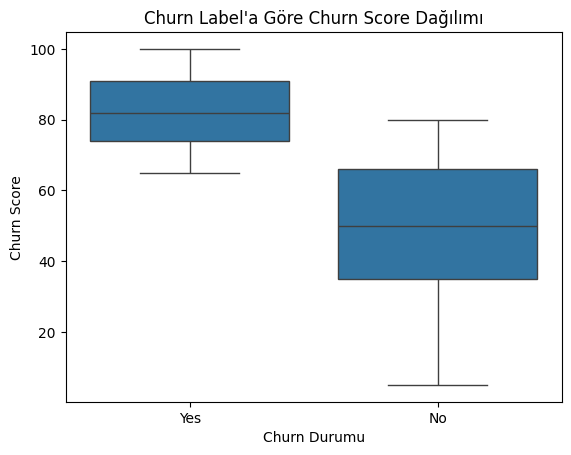

In [85]:
sns.boxplot(data=df, x="Churn Label", y="Churn Score")

plt.title("Churn Label'a Göre Churn Score Dağılımı")
plt.xlabel("Churn Durumu")
plt.ylabel("Churn Score")

plt.show()


# Churn Score modelde kullanılmalı mı? 
 istatistiksel tesine bakalım.
Churn Score ile Churn Label İlişkisinin İstatistiksel Testi

Churn Score ile Churn Label arasındaki gözlenen ilişkinin istatistiksel olarak anlamlı olup olmadığını değerlendirmek için Chi-square bağımsızlık testi uygulanacaktır.

Bu testte Churn Score, daha önce oluşturduğumuz skor grupları üzerinden kategorik bir değişken olarak ele alınacaktır.

 H₀: Churn Score grubu ile Churn Label arasında anlamlı bir ilişki yoktur.
 H₁: Churn Score grubu ile Churn Label arasında anlamlı bir ilişki vardır.

Önce Churn Score değerlerini gruplara ayıracağız. Sonra bu gruplar ile Churn Label arasındaki müşteri sayılarını bir çapraz tablo haline getireceğiz.
Ardından Chi-square testiyle bu iki değişken arasında istatistiksel olarak anlamlı bir ilişki olup olmadığını kontrol edeceğiz.

In [86]:
from scipy.stats import chi2_contingency #scipy kütüphanesinin istatististik bölümünden chi2_contşngency fonk çağırdık.
score_groups = pd.cut(#sayısal değerleri belirlediğimiz aralıklara bölüyoruz
    df["Churn Score"],#hangi sütunun
    bins=[0, 20, 40, 60, 80, 100],#böldüğümüz değerler
    labels=["0-20", "21-40", "41-60", "61-80", "81-100"] #adlandırmalar
)
contingency_table = pd.crosstab(#burada iki bilgiyi çaprazlıyoruz Score Group x Churn Label
    score_groups,
    df["Churn Label"]
)
chi2, p, dof, expected = chi2_contingency(contingency_table)
print("Chi-square:", chi2)
print("p-value:", p)
#asıl test kodun son kısmında:chi2 ->Chi-square test istatistiği p->p-value dof->serbestlik derecesi expected->değişkenler arasında ilişki olmasaydı bekleyeceğimiz müşteri sayıları

Chi-square: 4208.881381502739
p-value: 0.0


4208.881 Bu, Chi-square test istatistiği.
Bu sayı, gözlemlediğimiz dağılımın değişkenler bağımsız olsaydı bekleyeceğimiz dağılımdan ne kadar uzak olduğunu ölçen test istatistiğidir.
Değerin oldukça büyük çıkması, bizim gözlemlediğimiz Score_Group dağılımı ile Churn Label dağılımının bağımsızlık varsayımından ciddi şekilde uzak olduğunu gösteriyor.

Ama asıl kararımızı p-value üzerinden vereceğiz.
 p-value = 0.0 ne demek? Burada Python’un gösterdiği 0.0, gerçek matematiksel anlamda p’nin kesinlikle sıfır olduğu anlamına gelmez.Büyük ihtimalle değer o kadar küçük ki Python ekranda 0.0 olarak gösteriyor.

Örneğin gerçek değer 0.000000000001 gibi çok küçük bir sayı olabilir.

Bizim kullandığımız yaygın anlamlılık seviyesi:

α = 0.05

Karar kuralımız:

 p < 0.05 → H₀ reddedilir.aralarında anlamlı bir ilişki yoktur ifadesi reddedildi
 p ≥ 0.05 → H₀ reddedilemez.

Churn Score grubu ile Churn Label arasında istatistiksel olarak anlamlı bir ilişki olduğuna dair çok güçlü kanıt var.

Yani daha önce sadece veriye bakarak gördüğümüz ilişki, yaptığımız istatistiksel testte de desteklenmiş oluyor.

Ama çok önemli bir nokta:Bu test bize “Churn Score, churn’e sebep oluyor” demez.

Sadece:“Bu iki değişken bağımsız görünmüyor; aralarında istatistiksel olarak anlamlı bir ilişki var.”

Churn Score’un Modelleme Açısından Değerlendirilmesi

Churn Score ile Churn Label arasında güçlü ve istatistiksel olarak anlamlı bir ilişki olduğu görülmüştür.

Ancak bir makine öğrenmesi modelinde kullanılacak değişkenlerin, tahmin yapılmadan önce elde edilebilir bilgiler olması gerekir.Bu nedenle Churn Score değişkeninin churn gerçekleşmeden önce mevcut olan bir bilgi mi, yoksa churn sonucuyla ilişkili olarak oluşturulmuş bir skor mu olduğu ayrıca değerlendirilmelidir.

Bu aşamada değişkeni hemen silmek yerine, modelleme öncesinde veri sızıntısı (data leakage) açısından incelenmesine karar verilmiştir.


# Sayısal Değişkenlerde Aykırı Değerlerin İncelenmesi

Veri kalitesini değerlendirmek amacıyla sayısal değişkenlerde aykırı değerler incelenecektir.

Aykırı değerlerin doğrudan hatalı kabul edilmesi yerine, öncelikle bu değerlerin veri setindeki dağılımı ve iş anlamı değerlendirilecektir.

Bu aşamada özellikle Tenure Months, Monthly Charges, Total Charges, Churn Score ve CLTV değişkenleri incelenecektir.

In [87]:
df[[
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
    "Churn Score",
    "CLTV"
]].describe()
#describe():count,mean,std,min,max,%25,%50,%75 değerlerini verir


,Tenure Months,Monthly Charges,Total Charges,Churn Score,CLTV
count,7043.000000,7043.000000,7032.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2283.300441,58.699418,4400.295755
std,24.559481,30.090047,2266.771362,21.525131,1183.057152
min,0.000000,18.250000,18.800000,5.000000,2003.000000
25%,9.000000,35.500000,401.450000,40.000000,3469.000000
50%,29.000000,70.350000,1397.475000,61.000000,4527.000000
75%,55.000000,89.850000,3794.737500,75.000000,5380.500000
max,72.000000,118.750000,8684.800000,100.000000,6500.000000


#  IQR yöntemiyle aykırı değerleri belirleme

Şu ana kadar describe() ile genel dağılıma baktık. Orada bariz bir hata görmedik. Şimdi bunu ölçülebilir bir yöntemle kontrol edeceğiz.

* IQR mantığı

IQR, verinin ortadaki %50’lik bölümünün genişliğidir.

Formül:IQR = Q3 − Q1

Sonra aykırı değer sınırlarını şöyle belirleriz:

 Alt sınır = Q1 − 1.5 × IQR
 Üst sınır = Q3 + 1.5 × IQR

Bu sınırların dışındaki değerler istatistiksel olarak aykırı adaylarıdır.

“Aykırı çıktı” = “yanlış çıktı” değildir. Önce tespit edeceğiz, sonra iş açısından değerlendireceğiz.

Önce sadece Monthly Charges üzerinden öğrenelim


# Monthly Charges İçin IQR ile Aykırı Değer Tespiti

Monthly Charges değişkeninde istatistiksel olarak aykırı kabul edilebilecek değerleri belirlemek için IQR yöntemi kullanılacaktır.Öncelikle 25. yüzdelik değer (Q1) ve 75. yüzdelik değer (Q3) hesaplanacak, ardından IQR ve aykırı değer sınırları belirlenecektir.Bu yöntem sonucunda bulunan değerler doğrudan silinmeyecek; önce bu değerlerin iş açısından anlamlı olup olmadığı değerlendirilecektir.
 

In [89]:
Q1 = df["Monthly Charges"].quantile(0.25)
Q3 = df["Monthly Charges"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Alt sınır:", lower_bound)
print("Üst sınır:", upper_bound)

#.quantile(0.25) → 25. yüzdelik değeri, yani Q1’i bulur.
#.quantile(0.75) → 75. yüzdelik değeri, yani Q3’ü bulur.
# Q3 - Q1 → IQR’ı hesaplar.
# 1.5  IQR → IQR’ın 1.5 katını hesaplar.
# Q1’den bunu çıkarınca alt sınır,
# * Q3’e ekleyince üst sınır elde edilir.

Q1: 35.5
Q3: 89.85
IQR: 54.349999999999994
Alt sınır: -46.02499999999999
Üst sınır: 171.375


 Q1 = 35.5
 Q3 = 89.85
 IQR = 54.35
 Alt sınır = -46.025
 Üst sınır = 171.375

1. IQR = 54.35 ne anlatıyor?Ortadaki %50’lik Monthly Charges verisinin genişliği:89.85 − 35.5 = 54.35

Yani müşterilerin ortadaki yarısının aylık ücretleri 35.5 ile 89.85 arasında.

2. Alt sınır neden negatif çıktı?Matematiksel olarak: 35.5 − 1.5 × 54.35 = -46.025 Ama Monthly Charges için negatif ücret zaten mantıksız.

Burada önemli olan şu:Veri setimizde zaten negatif Monthly Charges olmadığını daha önce kontrol etmiştik.Dolayısıyla alt sınırın negatif olması bizim için problem oluşturmuyor.

3. Üst sınır daha önemli

Üst sınır: 171.375 IQR yöntemine göre Monthly Charges değeri 171.375’in üzerinde olsaydı, istatistiksel olarak aykırı değer adayı kabul edecektik.

Ama veri setimizde maksimum:118.75

Yani:118.75 < 171.375 Dolayısıyla Monthly Charges açısından IQR yöntemine göre aykırı değer adayı yok.

Monthly Charges için:

IQR yöntemine göre aykırı değer tespit edilmemiştir.

Ve bu değerleri silmiyoruz.

